# Deformacje terenu w Salonikach — anomalie i klasy zachowania punktów PS (EGMS)

**Projekt grupowy:** Kamila Matynia, Rafał Złoza, Amelia Hajduga

Zakres projektu:

1. **Analiza punktów PS (EGMS)** — wykrywanie anomalii (Isolation Forest) i klasteryzacja (K-means, 4 klasy).
2. **Mapa 4 klas** — gdzie leżą punkty z poszczególnych klas.
3. **Analiza budynków** — powiązanie anomalii i klas z budynkami.
4. **Interpretacja wyników.**
5. **Wyniki w CSV / GPKG** do QGIS i do oddania.

Dane:
- EGMS Ortho (L3), 2020–2024: https://egms.land.copernicus.eu/
- Budynki EUBUCCO v0.2: https://eubucco.com/data/download/v0.2
- Dokumentacja EGMS: https://land.copernicus.eu/en/products/european-ground-motion-service?tab=documentation

Kolejność uruchamiania: od góry do dołu (*Run all*). Notatnik działa lokalnie (pliki w `data/`) i w Colabie (pliki wgrane obok notatnika).

## 0. Ustawienia

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Folder projektu: lokalnie notatnik leży w notebooks/, w Colabie pliki są obok notatnika
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = next(
    (d for d in [ROOT / "data" / "do_colaba", ROOT / "data", ROOT]
     if (d / "thessaloniki_points.csv").exists()),
    ROOT,
)
RESULTS_DIR = ROOT / "results"
MAPS_DIR = ROOT / "maps"
RESULTS_DIR.mkdir(exist_ok=True)
MAPS_DIR.mkdir(exist_ok=True)

POINTS_FILE = DATA_DIR / "thessaloniki_points.csv"
BUILDINGS_FILE = DATA_DIR / "thessaloniki_buildings.gpkg"

CRS = "EPSG:3035"          # układ współrzędnych EGMS (ETRS89-LAEA)
RANDOM_STATE = 42
ANOMALY_SHARE = 0.05       # 5% PS o najwyższym anomaly_score uznajemy za anomalne
K_FINAL = 4                # liczba klas K-means (wymaganie projektu)
MAX_DISTANCE = 50          # [m] przypisanie PS do budynku — połowa oczka siatki EGMS Ortho (100 m)


def save_fig(name, **kwargs):
    """Zapis wykresu do maps/ — z ponowieniem, gdy plik jest chwilowo zablokowany (Windows)."""
    import time
    for _ in range(5):
        try:
            plt.savefig(MAPS_DIR / name, **kwargs)
            return
        except OSError:
            time.sleep(1)
    print("Nie udało się zapisać", name, "— zamknij plik, jeśli jest otwarty")


print("Dane:", DATA_DIR)
print("Wyniki:", RESULTS_DIR)
print("Mapy:", MAPS_DIR)

Dane: C:\Users\yosef\pi\data\do_colaba
Wyniki: C:\Users\yosef\pi\results
Mapy: C:\Users\yosef\pi\maps


# 1. Dane PS — import i kontrola

In [2]:
df = pd.read_csv(POINTS_FILE)

# Nazwy kolumn skrócone przy zapisie do shapefile -> pełne nazwy
df = df.rename(columns={
    "height_ort": "height_ortho",
    "mean_veloc": "mean_velocity",
    "mean_vel_1": "mean_velocity_std",
    "accelerati": "acceleration",
    "accelera_1": "acceleration_std",
    "seasonalit": "seasonality",
    "seasonal_1": "seasonality_std",
    "gnss_veloc": "gnss_velocity_n",
    "gnss_vel_1": "gnss_velocity_e",
    "gnss_vel_2": "gnss_velocity_u",
})

# Kolumny szeregu czasowego mają nazwy w formacie RRRRMMDD
date_cols = [c for c in df.columns if str(c).isdigit() and len(str(c)) == 8]
dates = pd.to_datetime(date_cols, format="%Y%m%d")

print("Liczba punktów PS:", len(df))
print("Liczba obserwacji w szeregu:", len(date_cols))
print("Okres:", dates.min().date(), "–", dates.max().date())
print("Braki w szeregach czasowych:", int(df[date_cols].isna().sum().sum()))
print("Zduplikowane pid:", int(df["pid"].duplicated().sum()))

Liczba punktów PS: 5625
Liczba obserwacji w szeregu: 303
Okres: 2020-01-03 – 2024-12-19
Braki w szeregach czasowych: 0
Zduplikowane pid: 0


In [3]:
# Pojedyncze braki w szeregu uzupełniamy interpolacją w czasie,
# żeby każdy PS miał kompletny szereg do wyznaczania trendów
if df[date_cols].isna().any().any():
    df[date_cols] = df[date_cols].interpolate(axis=1, limit_direction="both")

basic_features = ["mean_velocity", "acceleration", "seasonality", "rmse_ts"]
df[basic_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mean_velocity,5625.0,-2.95,3.62,-26.90,-3.40,-1.60,-0.80,2.70
acceleration,5625.0,0.28,0.81,-3.88,-0.18,0.17,0.67,5.58
seasonality,5625.0,1.50,1.39,0.00,0.70,1.10,1.80,15.50
rmse_ts,5625.0,1.30,0.75,0.30,0.70,1.10,1.70,4.30


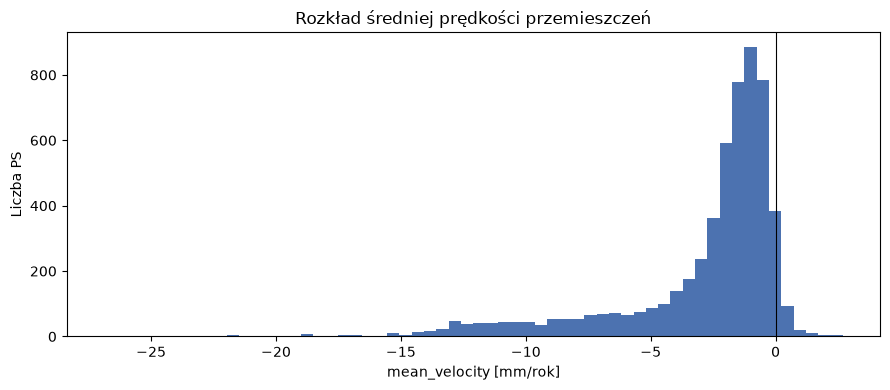

In [4]:
plt.figure(figsize=(9, 4))
plt.hist(df["mean_velocity"], bins=60, color="#4C72B0")
plt.axvline(0, color="k", linewidth=0.8)
plt.xlabel("mean_velocity [mm/rok]")
plt.ylabel("Liczba PS")
plt.title("Rozkład średniej prędkości przemieszczeń")
plt.tight_layout()
save_fig("histogram_mean_velocity.png", dpi=150)
plt.show()

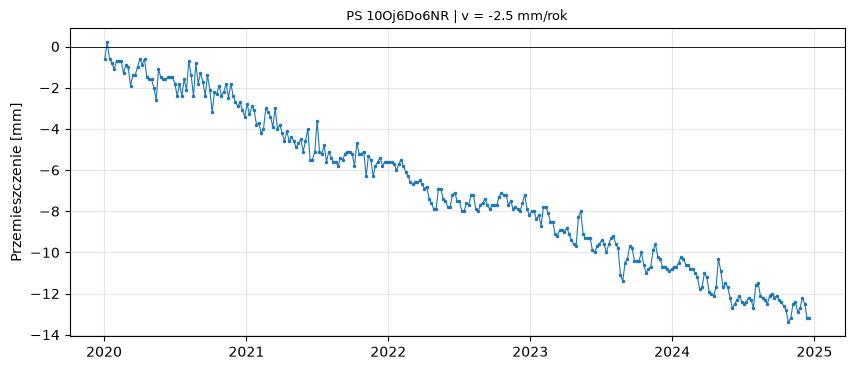

In [5]:
def plot_ps(pid, ax=None):
    row = df.loc[df["pid"] == pid].iloc[0]
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    ax.plot(dates, row[date_cols].astype(float).values, marker=".", markersize=3, linewidth=0.8)
    ax.axhline(0, color="k", linewidth=0.6)
    ax.set_ylabel("Przemieszczenie [mm]")
    ax.set_title(f"PS {pid} | v = {row['mean_velocity']:.1f} mm/rok", fontsize=9)
    ax.grid(alpha=0.3)
    return ax

plot_ps(df.iloc[0]["pid"])
plt.show()

# 2. Cechy szeregów czasowych

Model nie dostaje całego szeregu, tylko kilka **interpretowalnych cech**:

| cecha | znaczenie |
|---|---|
| `trend`, `trend_R2` | trend liniowy całego okresu [mm/rok] i jego dopasowanie |
| `trend_RRRR` | trend w danym roku [mm/rok] |
| `annual_trend_std` | zmienność trendów rocznych — czy tempo zmienia się między latami |
| `baseline_velocity` | trend przed ostatnimi 12 miesiącami |
| `recent_velocity` | trend z ostatnich 12 miesięcy |
| `trend_change` | `recent_velocity − baseline_velocity`; ujemna = osiadanie przyspieszyło |

Trendy liczymy jedną regresją dla wszystkich PS naraz (macierzowo), co jest dużo szybsze niż pętla po punktach.

In [6]:
def linear_trend(values, t):
    """Trend liniowy (nachylenie [mm/rok]) i R² dla wielu szeregów naraz.

    values: macierz (liczba PS × liczba dat), t: czas w latach.
    """
    y = np.asarray(values, dtype=float)
    t = np.asarray(t, dtype=float)
    tc = t - t.mean()
    yc = y - y.mean(axis=1, keepdims=True)

    slope = yc @ tc / (tc @ tc)
    residuals = yc - np.outer(slope, tc)
    ss_tot = (yc ** 2).sum(axis=1)
    r2 = np.where(ss_tot > 0, 1 - (residuals ** 2).sum(axis=1) / np.where(ss_tot > 0, ss_tot, 1), np.nan)
    return slope, r2


def years_from_start(d):
    return ((d - d.min()).days / 365.25).to_numpy()


Y = df[date_cols].to_numpy(dtype=float)

# Trend całego okresu
df["trend"], df["trend_R2"] = linear_trend(Y, years_from_start(dates))

# Trendy roczne
years = sorted(pd.Index(dates.year).unique())
yearly_trend_cols = []
for year in years:
    mask = np.asarray(dates.year == year)
    col = f"trend_{year}"
    df[col], _ = linear_trend(Y[:, mask], years_from_start(dates[mask]))
    yearly_trend_cols.append(col)

df["annual_trend_std"] = df[yearly_trend_cols].std(axis=1)

# Ostatnie 12 miesięcy względem wcześniejszego okresu
recent_start = dates.max() - pd.DateOffset(years=1)
baseline_mask = np.asarray(dates < recent_start)
recent_mask = ~baseline_mask

df["baseline_velocity"], _ = linear_trend(Y[:, baseline_mask], years_from_start(dates[baseline_mask]))
df["recent_velocity"], _ = linear_trend(Y[:, recent_mask], years_from_start(dates[recent_mask]))
df["trend_change"] = df["recent_velocity"] - df["baseline_velocity"]

print("Lata:", years)
print("Okres bazowy:", dates[baseline_mask].min().date(), "–", dates[baseline_mask].max().date())
print("Ostatnie 12 mies.:", dates[recent_mask].min().date(), "–", dates[recent_mask].max().date())
print("Korelacja trend vs mean_velocity (EGMS):", round(df["trend"].corr(df["mean_velocity"]), 3))

df[["pid", "mean_velocity", "trend", "trend_R2", "annual_trend_std", "trend_change"]].head()

Lata: [2020, 2021, 2022, 2023, 2024]
Okres bazowy: 2020-01-03 – 2023-12-13
Ostatnie 12 mies.: 2023-12-19 – 2024-12-19
Korelacja trend vs mean_velocity (EGMS): 0.999


,pid,mean_velocity,trend,trend_R2,annual_trend_std,trend_change
0,10Oj6Do6NR,-2.5,-2.528203,0.980315,0.380806,0.225001
1,10Oj6Do6NS,-2.3,-2.237577,0.942343,0.802373,2.287243
2,10Oj6Do6NT,-2.6,-2.542851,0.957371,0.742317,1.201675
3,10Oj6Do6NU,-3.0,-2.990431,0.966717,0.873345,2.229926
4,10Oj6Do6NV,-3.6,-3.612164,0.962724,1.216038,2.430872


Wysoka korelacja `trend` z `mean_velocity` z EGMS potwierdza, że nasze trendy są liczone poprawnie.

# 3. Wybór cech do modeli

Do obu modeli (Isolation Forest i K-means) używamy tych samych trzech cech:

- `mean_velocity` — przeciętne tempo ruchu,
- `acceleration` — zmiana prędkości w całym okresie (parametr EGMS),
- `trend_change` — zmiana tempa w ostatnich 12 miesiącach.

`rmse_ts`, `seasonality` i `trend_R2` zostają poza modelem i służą do kontroli wyników.

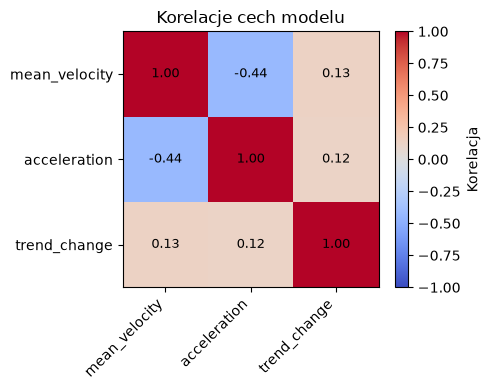

PS z kompletem cech: 5625 / 5625


In [7]:
model_features = ["mean_velocity", "acceleration", "trend_change"]
control_features = ["rmse_ts", "trend_R2", "seasonality"]

corr = df[model_features].corr()

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
fig.colorbar(im, label="Korelacja")
ax.set_xticks(range(len(model_features)), model_features, rotation=45, ha="right")
ax.set_yticks(range(len(model_features)), model_features)
for i in range(len(model_features)):
    for j in range(len(model_features)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Korelacje cech modelu")
plt.tight_layout()
plt.show()

# Modele uruchamiamy tylko dla PS z kompletem cech
mask_model = df[model_features].notna().all(axis=1)
print("PS z kompletem cech:", mask_model.sum(), "/", len(df))

# 4. Wykrywanie anomalii — Isolation Forest

Isolation Forest (uczenie nienadzorowane) wskazuje PS o **nietypowej kombinacji cech** na tle całego zbioru.
`anomaly_score` — im wyższy, tym bardziej nietypowy punkt. Za anomalne przyjmujemy umownie 5% PS z najwyższym wynikiem — to próg wyboru punktów do dalszej analizy, a nie stwierdzenie, że deformacja jest groźna.

In [8]:
X = df.loc[mask_model, model_features]

iso_forest = IsolationForest(n_estimators=300, contamination="auto", random_state=RANDOM_STATE)
iso_forest.fit(X)

# Odwrócenie znaku: wyższy wynik = bardziej nietypowy PS (przypisanie po indeksie)
df["anomaly_score"] = np.nan
df.loc[mask_model, "anomaly_score"] = -iso_forest.score_samples(X)

threshold = df["anomaly_score"].quantile(1 - ANOMALY_SHARE)
df["anomaly"] = (df["anomaly_score"] >= threshold).astype(int)

print("Próg anomaly_score:", round(threshold, 3))
print("Liczba PS anomalnych:", df["anomaly"].sum(), "/", len(df))

Próg anomaly_score: 0.575
Liczba PS anomalnych: 282 / 5625


### Kontrola wyników

1. Czy anomalie to tylko punkty o złej jakości (wysokie `rmse_ts`)?
2. Czy model wskazuje wyłącznie najszybciej osiadające punkty?
3. Jak wyglądają szeregi czasowe najbardziej nietypowych PS?

In [9]:
print("Korelacja anomaly_score vs rmse_ts:", round(df["anomaly_score"].corr(df["rmse_ts"]), 3))

top20_model = set(df.nlargest(20, "anomaly_score")["pid"])
top20_velocity = set(df.nsmallest(20, "mean_velocity")["pid"])
print("Wspólne PS w TOP20 (anomaly_score vs najbardziej ujemne mean_velocity):",
      len(top20_model & top20_velocity), "/ 20")

print()
print("Mediany cech: PS anomalne vs pozostałe")
df.groupby("anomaly")[model_features + control_features].median().round(2)

Korelacja anomaly_score vs rmse_ts: 0.297
Wspólne PS w TOP20 (anomaly_score vs najbardziej ujemne mean_velocity): 13 / 20

Mediany cech: PS anomalne vs pozostałe


,mean_velocity,acceleration,trend_change,rmse_ts,trend_R2,seasonality
anomaly,,,,,,
0,-1.6,0.16,-0.38,1.1,0.68,1.1
1,-10.2,1.94,-8.37,1.8,0.87,3.8


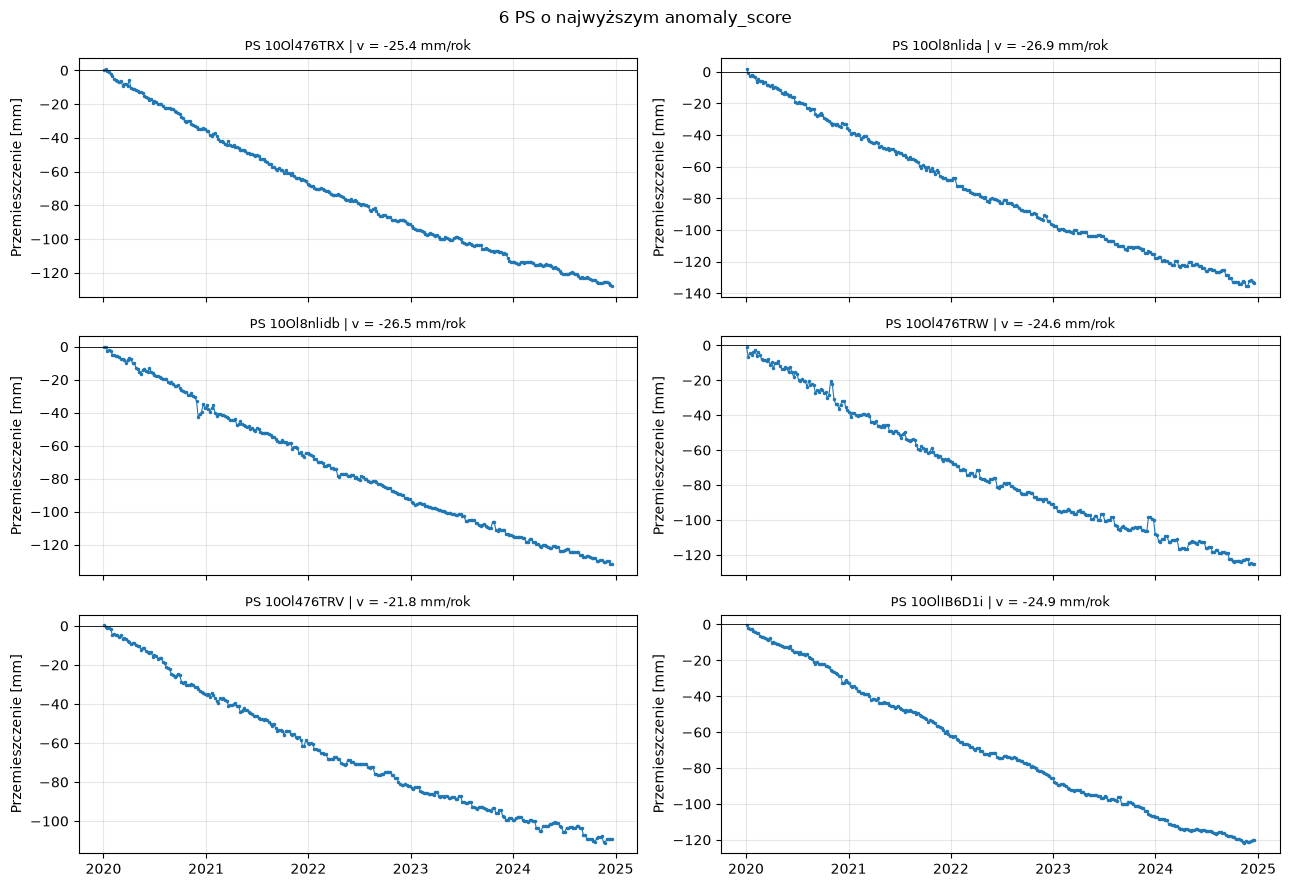

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
for ax, pid in zip(axes.flat, df.nlargest(6, "anomaly_score")["pid"]):
    plot_ps(pid, ax)
fig.suptitle("6 PS o najwyższym anomaly_score")
plt.tight_layout()
save_fig("szeregi_top_anomalie.png", dpi=150)
plt.show()

# 5. Klasteryzacja — K-means (4 klasy)

Cechy standaryzujemy (różne jednostki i rozrzut). Liczbę klastrów sprawdzamy dla `k = 2…8` metodą elbow i silhouette.

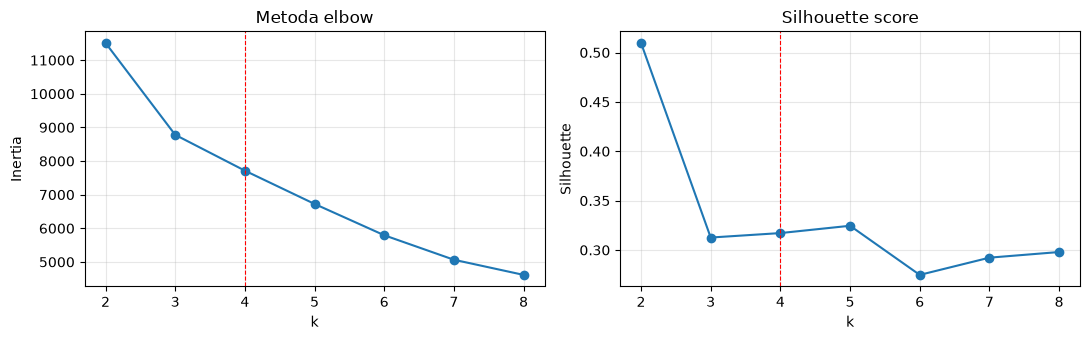

,k,inertia,silhouette
0,2,11511.704,0.510
1,3,8779.299,0.313
2,4,7713.803,0.317
3,5,6724.583,0.325
4,6,5793.377,0.275
5,7,5064.873,0.292
6,8,4614.355,0.298


In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_scaled, labels)})
results_k = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(results_k["k"], results_k["inertia"], marker="o")
axes[0].set(xlabel="k", ylabel="Inertia", title="Metoda elbow")
axes[1].plot(results_k["k"], results_k["silhouette"], marker="o")
axes[1].set(xlabel="k", ylabel="Silhouette", title="Silhouette score")
for ax in axes:
    ax.axvline(K_FINAL, color="red", linestyle="--", linewidth=0.8)
    ax.grid(alpha=0.3)
plt.tight_layout()
save_fig("dobor_k.png", dpi=150)
plt.show()

results_k.round(3)

### Wybór `k = 4`

Najwyższy silhouette zwykle daje `k = 2`, ale taki podział rozdziela jedynie punkty stabilne i osiadające. Przy `k = 4` silhouette jest podobny do sąsiednich wartości, spadek inertii po `k = 4` wyraźnie słabnie, a klasy dają się sensownie zinterpretować — dlatego (zgodnie z założeniem projektu) wybieramy 4 klasy.

In [12]:
kmeans = KMeans(n_clusters=K_FINAL, n_init=20, random_state=RANDOM_STATE)
raw_labels = kmeans.fit_predict(X_scaled)

# Numerujemy klasy 1–4 od najbardziej stabilnej do najszybciej osiadającej
# (numery K-means są przypadkowe, a taki porządek ułatwia legendę i interpretację)
tmp = pd.DataFrame({"raw": raw_labels, "v": X["mean_velocity"].to_numpy()})
order = tmp.groupby("raw")["v"].median().sort_values(ascending=False).index
relabel = {raw: i + 1 for i, raw in enumerate(order)}

df["cluster"] = pd.Series(pd.NA, index=df.index, dtype="Int64")
df.loc[mask_model, "cluster"] = [relabel[l] for l in raw_labels]

df["cluster"].value_counts().sort_index()

cluster
1    3076
2    1696
3     282
4     571
Name: count, dtype: Int64

In [13]:
def describe_cluster(v, tc, seas):
    """Nazwa klasy na podstawie median prędkości, zmiany trendu i sezonowości."""
    if v <= -5:
        name = "silne osiadanie"
    elif v <= -2:
        name = "umiarkowane osiadanie"
    elif v < 2:
        name = "stabilne / słabe osiadanie"
    else:
        name = "wypiętrzanie"
    if tc <= -2:
        name += ", przyspieszające"
    elif tc >= 2:
        name += ", zwalniające"
    # sezonowość wyraźnie wyższa niż typowa w całym zbiorze
    if seas >= 2 * df["seasonality"].median():
        name += ", silnie sezonowe"
    return name


cluster_summary = (
    df.groupby("cluster")
    .agg(
        n_PS=("pid", "count"),
        n_anomalies=("anomaly", "sum"),
        median_velocity=("mean_velocity", "median"),
        median_acceleration=("acceleration", "median"),
        median_trend_change=("trend_change", "median"),
        median_seasonality=("seasonality", "median"),
        median_rmse=("rmse_ts", "median"),
        median_anomaly_score=("anomaly_score", "median"),
    )
)
cluster_summary["percent_anomalies"] = (cluster_summary["n_anomalies"] / cluster_summary["n_PS"] * 100).round(1)
cluster_summary["cluster_name"] = [
    f"{c}: {describe_cluster(r.median_velocity, r.median_trend_change, r.median_seasonality)}"
    for c, r in cluster_summary.iterrows()
]

df["cluster_name"] = df["cluster"].map(cluster_summary["cluster_name"])

cluster_summary.round(2)

,n_PS,n_anomalies,median_velocity,median_acceleration,median_trend_change,median_seasonality,median_rmse,median_anomaly_score,percent_anomalies,cluster_name
cluster,,,,,,,,,,
1,3076,15,-1.3,0.29,1.02,1.0,1.0,0.39,0.5,1: stabilne / słabe osiadanie
2,1696,71,-1.6,-0.31,-3.29,1.3,1.3,0.42,4.2,"2: stabilne / słabe osiadanie, przyspieszające"
3,282,118,-8.6,1.82,-6.71,4.9,1.4,0.56,41.8,"3: silne osiadanie, przyspieszające, silnie se..."
4,571,78,-10.0,0.81,-0.47,1.5,0.9,0.50,13.7,4: silne osiadanie


Nazwy klas są nadawane automatycznie z median (`mean_velocity`, `trend_change`, `seasonality`), więc pasują do danych także po ponownym uruchomieniu. Udział anomalii w klasach pokazuje, które typy zachowania Isolation Forest uznaje za nietypowe.

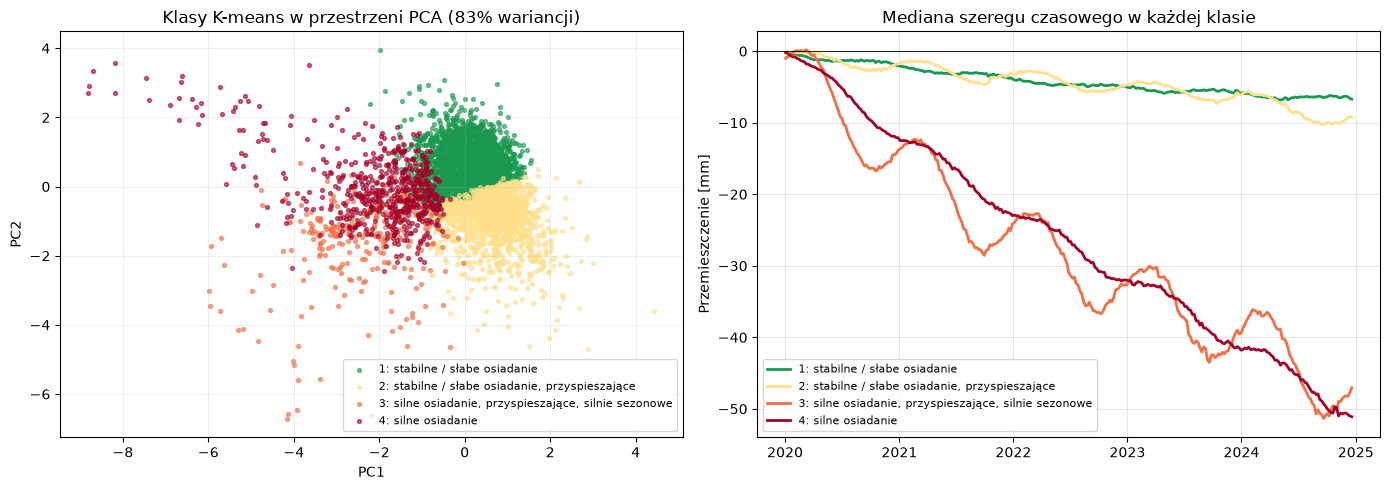

In [14]:
# Wizualizacja klas w 2D (PCA) i średni przebieg szeregu w każdej klasie
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
clusters_model = df.loc[mask_model, "cluster"].astype(int).to_numpy()

class_colors = {1: "#1a9850", 2: "#fee08b", 3: "#f46d43", 4: "#a50026"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for c in sorted(class_colors):
    m = clusters_model == c
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], s=8, alpha=0.6, color=class_colors[c],
                    label=cluster_summary.loc[c, "cluster_name"])
axes[0].set(xlabel="PC1", ylabel="PC2",
            title=f"Klasy K-means w przestrzeni PCA ({pca.explained_variance_ratio_.sum() * 100:.0f}% wariancji)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.2)

for c in sorted(class_colors):
    m = (df["cluster"] == c).to_numpy()
    axes[1].plot(dates, np.median(Y[m], axis=0), color=class_colors[c], linewidth=2,
                 label=cluster_summary.loc[c, "cluster_name"])
axes[1].axhline(0, color="k", linewidth=0.6)
axes[1].set(ylabel="Przemieszczenie [mm]", title="Mediana szeregu czasowego w każdej klasie")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
save_fig("klasy_pca_i_szeregi.png", dpi=150)
plt.show()

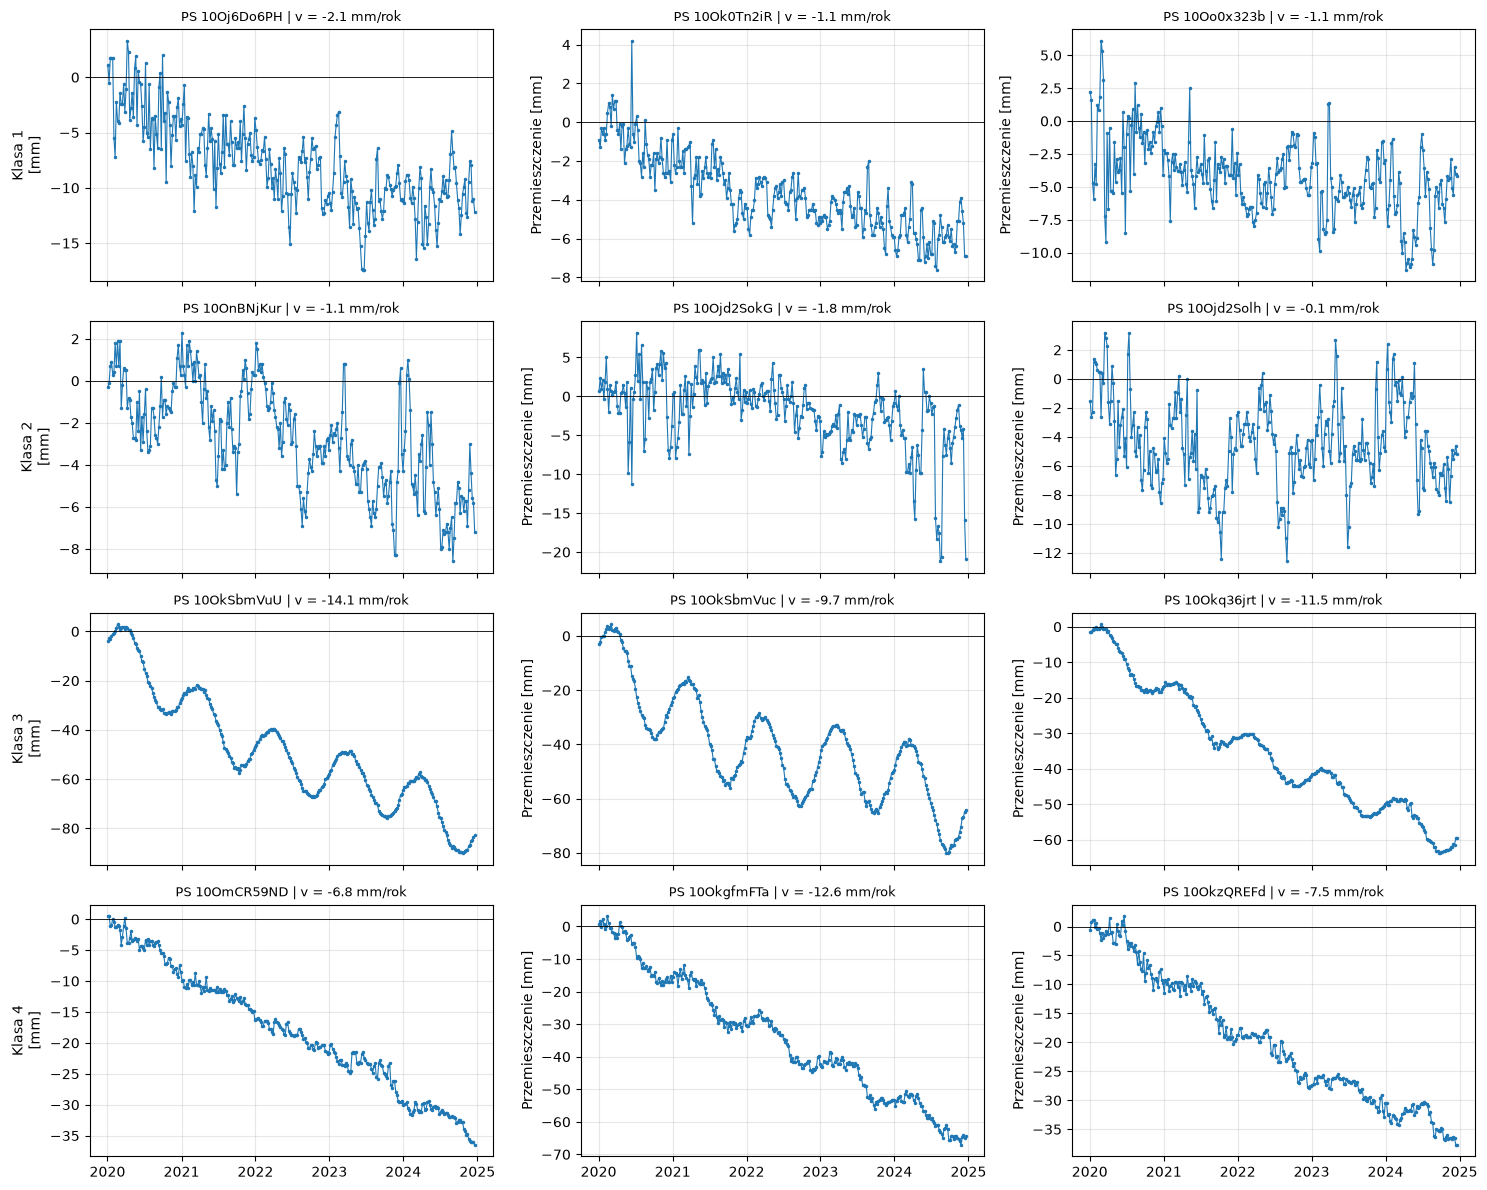

In [15]:
# Przykładowe szeregi z każdej klasy
fig, axes = plt.subplots(K_FINAL, 3, figsize=(15, 3 * K_FINAL), sharex=True)
for row_axes, c in zip(axes, sorted(class_colors)):
    sample = df[df["cluster"] == c].sample(n=3, random_state=RANDOM_STATE)
    for ax, pid in zip(row_axes, sample["pid"]):
        plot_ps(pid, ax)
    row_axes[0].set_ylabel(f"Klasa {c}\n[mm]")
plt.tight_layout()
plt.show()

# 6. Mapa 4 klas i anomalii — gdzie leżą punkty?

Punkty EGMS Ortho leżą w siatce 100 m, więc rysujemy je jako kwadraty 100 × 100 m. Anomalie (Isolation Forest) zaznaczamy czarnym obrysem. Podkład: OpenStreetMap.

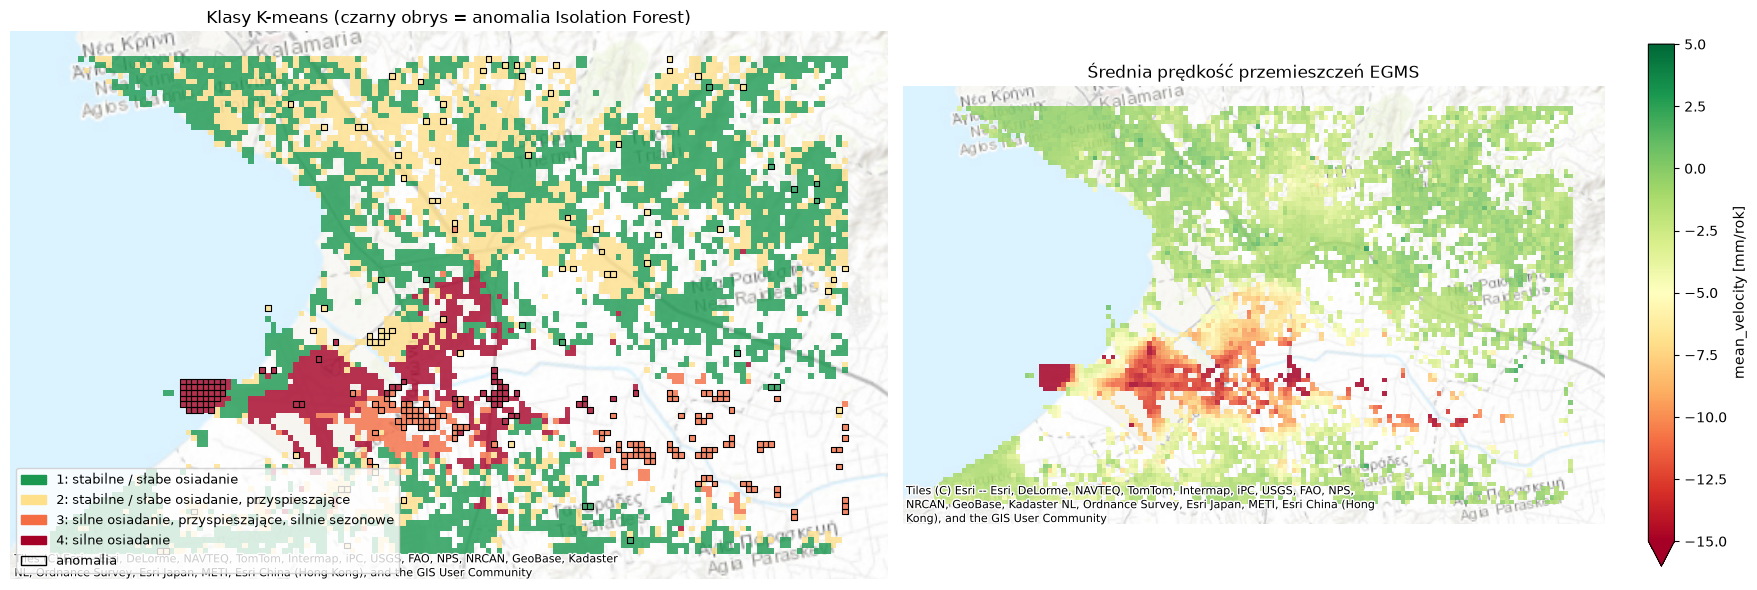

In [16]:
ps_gdf = gpd.GeoDataFrame(
    df.drop(columns=date_cols),
    geometry=gpd.points_from_xy(df["easting"], df["northing"]),
    crs=CRS,
)

# Kwadraty 100 × 100 m wokół punktów siatki (do mapy i QGIS)
ps_cells = ps_gdf.copy()
ps_cells["geometry"] = ps_gdf.buffer(50, cap_style="square")

try:
    import contextily as cx
except ImportError:
    cx = None
    print("Brak contextily — mapy bez podkładu (pip install contextily)")


def add_basemap(ax):
    if cx is not None:
        try:
            # Esri — kafelki OSM blokują pobieranie z Pythona
            cx.add_basemap(ax, crs=CRS, source=cx.providers.Esri.WorldTopoMap, alpha=0.7)
        except Exception as e:  # brak internetu
            print("Podkład niedostępny:", e)
    ax.set_axis_off()


fig, axes = plt.subplots(1, 2, figsize=(18, 9))

for c in sorted(class_colors):
    ps_cells[ps_cells["cluster"] == c].plot(
        ax=axes[0], color=class_colors[c], alpha=0.8, linewidth=0,
        label=cluster_summary.loc[c, "cluster_name"])
ps_cells[ps_cells["anomaly"] == 1].plot(ax=axes[0], facecolor="none", edgecolor="black", linewidth=0.8)
axes[0].set_title("Klasy K-means (czarny obrys = anomalia Isolation Forest)")
handles = [plt.Rectangle((0, 0), 1, 1, color=class_colors[c]) for c in sorted(class_colors)]
handles.append(plt.Rectangle((0, 0), 1, 1, facecolor="none", edgecolor="black"))
labels = [cluster_summary.loc[c, "cluster_name"] for c in sorted(class_colors)] + ["anomalia"]
axes[0].legend(handles, labels, loc="lower left", fontsize=9)
add_basemap(axes[0])

ps_cells.plot(ax=axes[1], column="mean_velocity", cmap="RdYlGn", vmin=-15, vmax=5,
              alpha=0.85, linewidth=0, legend=True,
              legend_kwds={"label": "mean_velocity [mm/rok]", "shrink": 0.6})
axes[1].set_title("Średnia prędkość przemieszczeń EGMS")
add_basemap(axes[1])

plt.tight_layout()
save_fig("mapa_klasy_i_predkosc.png", dpi=200, bbox_inches="tight")
plt.show()

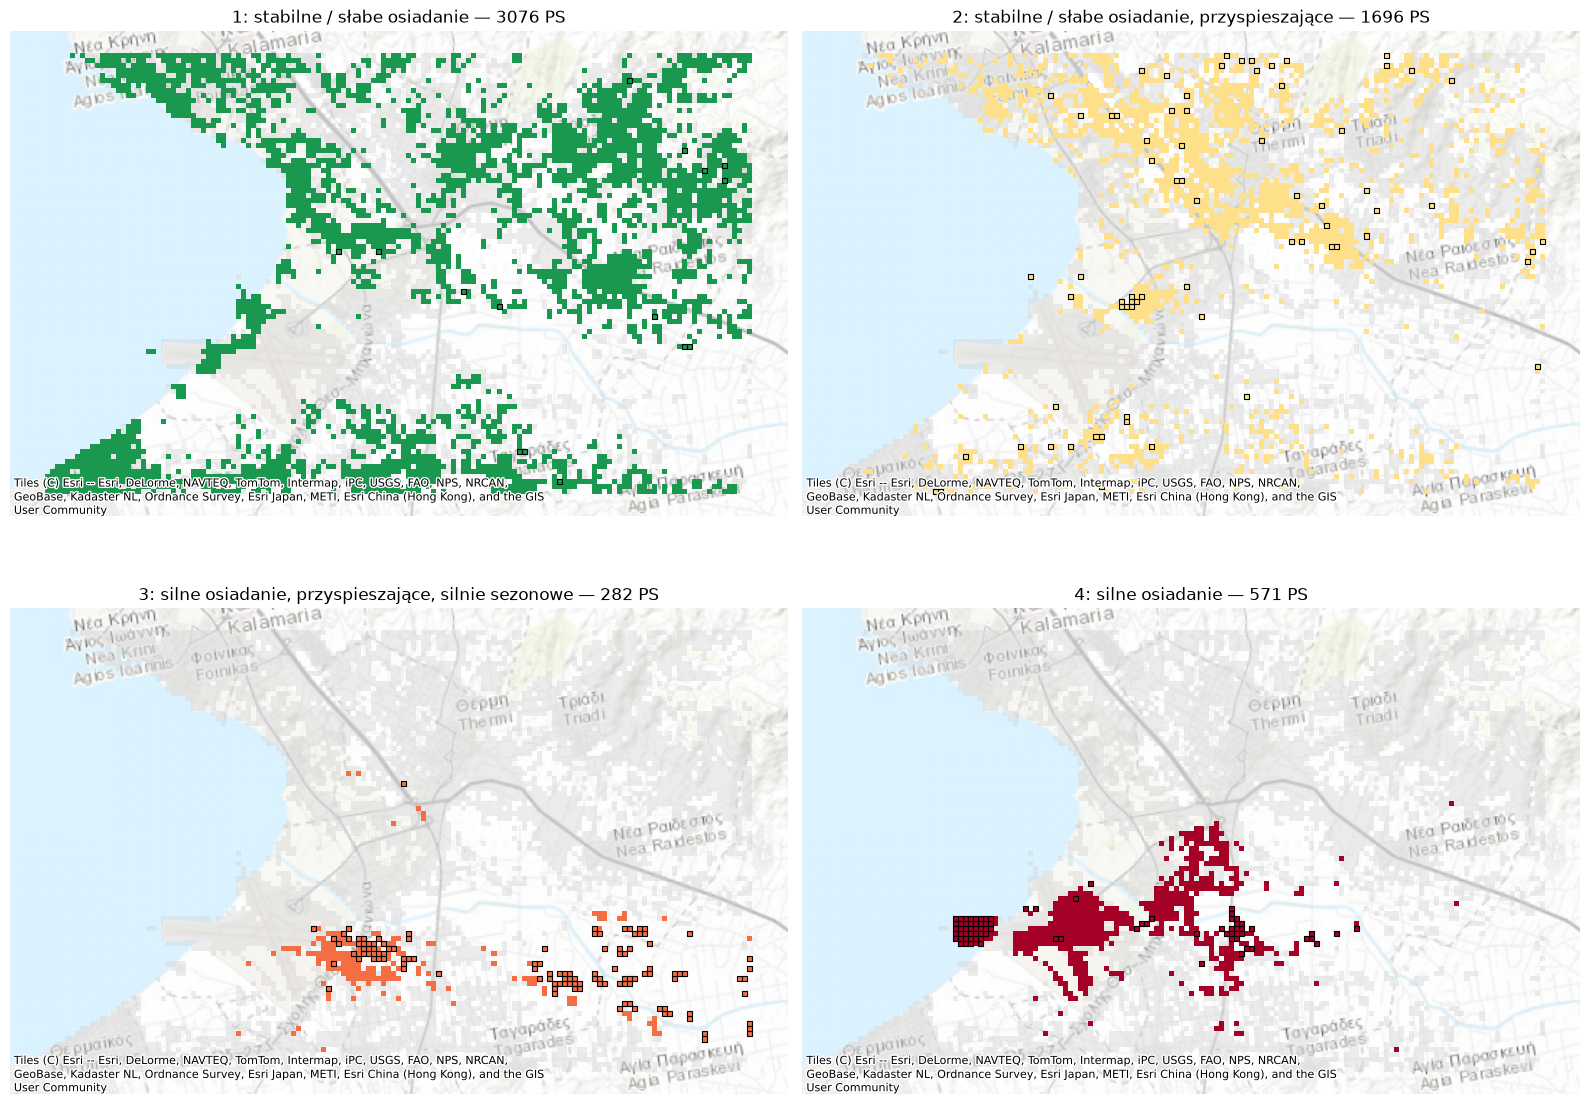

In [17]:
# Osobna mapa dla każdej klasy — łatwiej opisać lokalizację
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, c in zip(axes.flat, sorted(class_colors)):
    ps_cells.plot(ax=ax, color="lightgrey", alpha=0.4, linewidth=0)
    sel = ps_cells[ps_cells["cluster"] == c]
    sel.plot(ax=ax, color=class_colors[c], linewidth=0)
    sel[sel["anomaly"] == 1].plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.8)
    ax.set_title(f"{cluster_summary.loc[c, 'cluster_name']} — {len(sel)} PS")
    add_basemap(ax)
plt.tight_layout()
save_fig("mapa_klasy_osobno.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
# Położenie klas liczbowo: środek ciężkości (współrzędne geograficzne) i zasięg
loc = ps_gdf.to_crs("EPSG:4326")
loc["lon"], loc["lat"] = loc.geometry.x, loc.geometry.y

cluster_location = loc.groupby("cluster").agg(
    n_PS=("pid", "count"),
    lat_center=("lat", "median"),
    lon_center=("lon", "median"),
    lon_min=("lon", "min"),
    lon_max=("lon", "max"),
)
cluster_location["area_km2"] = ps_gdf.groupby("cluster").size() * 0.01   # 1 komórka = 0,01 km²
cluster_location["cluster_name"] = cluster_summary["cluster_name"]
cluster_location.round(4)

,n_PS,lat_center,lon_center,lon_min,lon_max,area_km2,cluster_name
cluster,,,,,,,
1,3076,40.5368,23.0177,22.9143,23.0931,30.76,1: stabilne / słabe osiadanie
2,1696,40.5458,23.0119,22.9208,23.0903,16.96,"2: stabilne / słabe osiadanie, przyspieszające"
3,282,40.5104,23.0002,22.9597,23.0817,2.82,"3: silne osiadanie, przyspieszające, silnie se..."
4,571,40.5215,22.9932,22.9458,23.0658,5.71,4: silne osiadanie


In [19]:
# Mapa interaktywna (HTML) — do otwarcia w przeglądarce / pokazania na prezentacji
try:
    import folium

    cells_wgs = ps_cells.to_crs("EPSG:4326")[
        ["pid", "cluster", "cluster_name", "mean_velocity", "trend_change", "anomaly", "anomaly_score", "geometry"]
    ].copy()
    cells_wgs["cluster"] = cells_wgs["cluster"].astype(float)
    m = cells_wgs.explore(
        column="cluster_name",
        cmap=[class_colors[c] for c in sorted(class_colors)],
        tooltip=["pid", "cluster_name", "mean_velocity", "trend_change", "anomaly", "anomaly_score"],
        # OSM blokuje kafelki dla pliku HTML otwieranego z dysku — używamy Esri
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles © Esri",
        style_kwds={"weight": 0, "fillOpacity": 0.7},
        name="Klasy K-means",
    )
    cells_wgs[cells_wgs["anomaly"] == 1].explore(
        m=m, color="black", style_kwds={"fill": False, "weight": 1.5}, name="Anomalie",
    )
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles © Esri", name="Zdjęcie satelitarne (Esri)", overlay=False,
    ).add_to(m)
    folium.LayerControl().add_to(m)
    m.save(MAPS_DIR / "mapa_interaktywna_PS.html")
    print("Zapisano:", MAPS_DIR / "mapa_interaktywna_PS.html")
except ImportError:
    print("Brak folium — pomijam mapę interaktywną (pip install folium)")

Zapisano: C:\Users\yosef\pi\maps\mapa_interaktywna_PS.html


# 7. Budynki — powiązanie anomalii i klas z budynkami

Każdemu budynkowi przypisujemy najbliższy PS w odległości do `MAX_DISTANCE = 50 m`.

**Uwaga metodyczna:** punkty EGMS Ortho to siatka 100 × 100 m (uśrednione przemieszczenia w komórce), a nie odbicia od konkretnych obiektów. Przy 50 m (połowa oczka) budynek dostaje punkt komórki, w której leży. Przypisany PS opisuje więc **ruch terenu w otoczeniu budynku**, a nie ruch samego budynku.

In [20]:
buildings = gpd.read_file(BUILDINGS_FILE)
print("Budynki wczytane:", len(buildings), "| CRS:", buildings.crs)

# Usunięcie powtarzających się geometrii i nadanie identyfikatorów
buildings = buildings.drop_duplicates(subset="geometry").reset_index(drop=True)
buildings["building_id"] = np.arange(1, len(buildings) + 1)
buildings = buildings.to_crs(CRS)

print("Budynki po usunięciu duplikatów:", len(buildings))
print(buildings.geom_type.value_counts())

Budynki wczytane: 21846 | CRS: EPSG:3035
Budynki po usunięciu duplikatów: 21846
MultiPolygon    21846
Name: count, dtype: int64


In [21]:
ps_for_join = ps_gdf[[
    "pid", "mean_velocity", "acceleration", "trend_change", "rmse_ts",
    "anomaly_score", "anomaly", "cluster", "cluster_name", "geometry",
]]

joined = gpd.sjoin_nearest(
    buildings[["building_id", "geometry"]],
    ps_for_join,
    how="left",
    max_distance=MAX_DISTANCE,
    distance_col="distance_PS",
)

# Budynek w tej samej odległości od kilku PS -> zostawiamy bardziej nietypowy PS
buildings_ps = (
    joined.drop(columns=["geometry", "index_right"], errors="ignore")
    .sort_values(["building_id", "distance_PS", "anomaly_score"], ascending=[True, True, False], na_position="last")
    .drop_duplicates(subset="building_id", keep="first")
)
buildings_ps["has_PS"] = buildings_ps["pid"].notna()

result = buildings.merge(buildings_ps, on="building_id", how="left")
result = gpd.GeoDataFrame(result, geometry="geometry", crs=CRS)

matched = result["has_PS"]
print("Wszystkie budynki:", len(result))
print(f"Budynki z PS do {MAX_DISTANCE} m:", matched.sum(), f"({matched.mean() * 100:.1f}%)")
print("Budynki bez PS:", (~matched).sum())
print("Wykorzystane unikalne PS:", result["pid"].nunique())
print("Mediana odległości:", round(result.loc[matched, "distance_PS"].median(), 1), "m")

Wszystkie budynki: 21846
Budynki z PS do 50 m: 18684 (85.5%)
Budynki bez PS: 3162
Wykorzystane unikalne PS: 3680
Mediana odległości: 30.3 m


In [22]:
buildings_summary = (
    result[matched]
    .groupby("cluster")
    .agg(
        n_buildings=("building_id", "count"),
        n_buildings_anomaly=("anomaly", "sum"),
        median_velocity=("mean_velocity", "median"),
    )
)
buildings_summary["percent_buildings"] = (buildings_summary["n_buildings"] / matched.sum() * 100).round(1)
buildings_summary["percent_anomaly"] = (buildings_summary["n_buildings_anomaly"] / buildings_summary["n_buildings"] * 100).round(1)
buildings_summary["cluster_name"] = cluster_summary["cluster_name"]

print("Budynki przy PS anomalnym:", int(result["anomaly"].fillna(0).sum()))
buildings_summary

Budynki przy PS anomalnym: 375


,n_buildings,n_buildings_anomaly,median_velocity,percent_buildings,percent_anomaly,cluster_name
cluster,,,,,,
1,12552,15.0,-1.3,67.2,0.1,1: stabilne / słabe osiadanie
2,4631,99.0,-1.7,24.8,2.1,"2: stabilne / słabe osiadanie, przyspieszające"
3,573,199.0,-8.0,3.1,34.7,"3: silne osiadanie, przyspieszające, silnie se..."
4,928,62.0,-8.5,5.0,6.7,4: silne osiadanie


In [23]:
# Budynki wymagające uwagi: przy PS anomalnym lub w klasie silnego osiadania,
# posortowane od najszybszego osiadania
risk = result[matched & ((result["anomaly"] == 1) | (result["cluster"] >= 3))].copy()
risk = risk.sort_values("mean_velocity")

print("Budynki wymagające uwagi:", len(risk))
risk[["building_id", "pid", "cluster_name", "mean_velocity", "trend_change", "anomaly", "anomaly_score", "distance_PS"]].head(20)

Budynki wymagające uwagi: 1615


,building_id,pid,cluster_name,mean_velocity,trend_change,anomaly,anomaly_score,distance_PS
9397,9398,10Ol8nlieQ,4: silne osiadanie,-23.5,-5.585291,1.0,0.633333,36.630162
20087,20088,10Ol8nlieQ,4: silne osiadanie,-23.5,-5.585291,1.0,0.633333,25.231829
10240,10241,10Ol8nlieQ,4: silne osiadanie,-23.5,-5.585291,1.0,0.633333,3.025103
10872,10873,10OlIB6D2a,4: silne osiadanie,-20.4,-0.637860,1.0,0.632446,27.474319
10309,10310,10OlIB6D2a,4: silne osiadanie,-20.4,-0.637860,1.0,0.632446,39.335089
10665,10666,10OlDUQxqW,4: silne osiadanie,-19.6,-0.569069,1.0,0.603548,27.399489
9854,9855,10OlDUQxqV,4: silne osiadanie,-19.5,2.559634,1.0,0.683683,31.316792
9115,9116,10OlIB6D2b,4: silne osiadanie,-19.1,2.761420,1.0,0.684677,39.279080
20069,20070,10OlIB6D2b,4: silne osiadanie,-19.1,2.761420,1.0,0.684677,32.331765
20241,20242,10OlDUQxqX,4: silne osiadanie,-19.0,2.846129,1.0,0.675834,42.578308


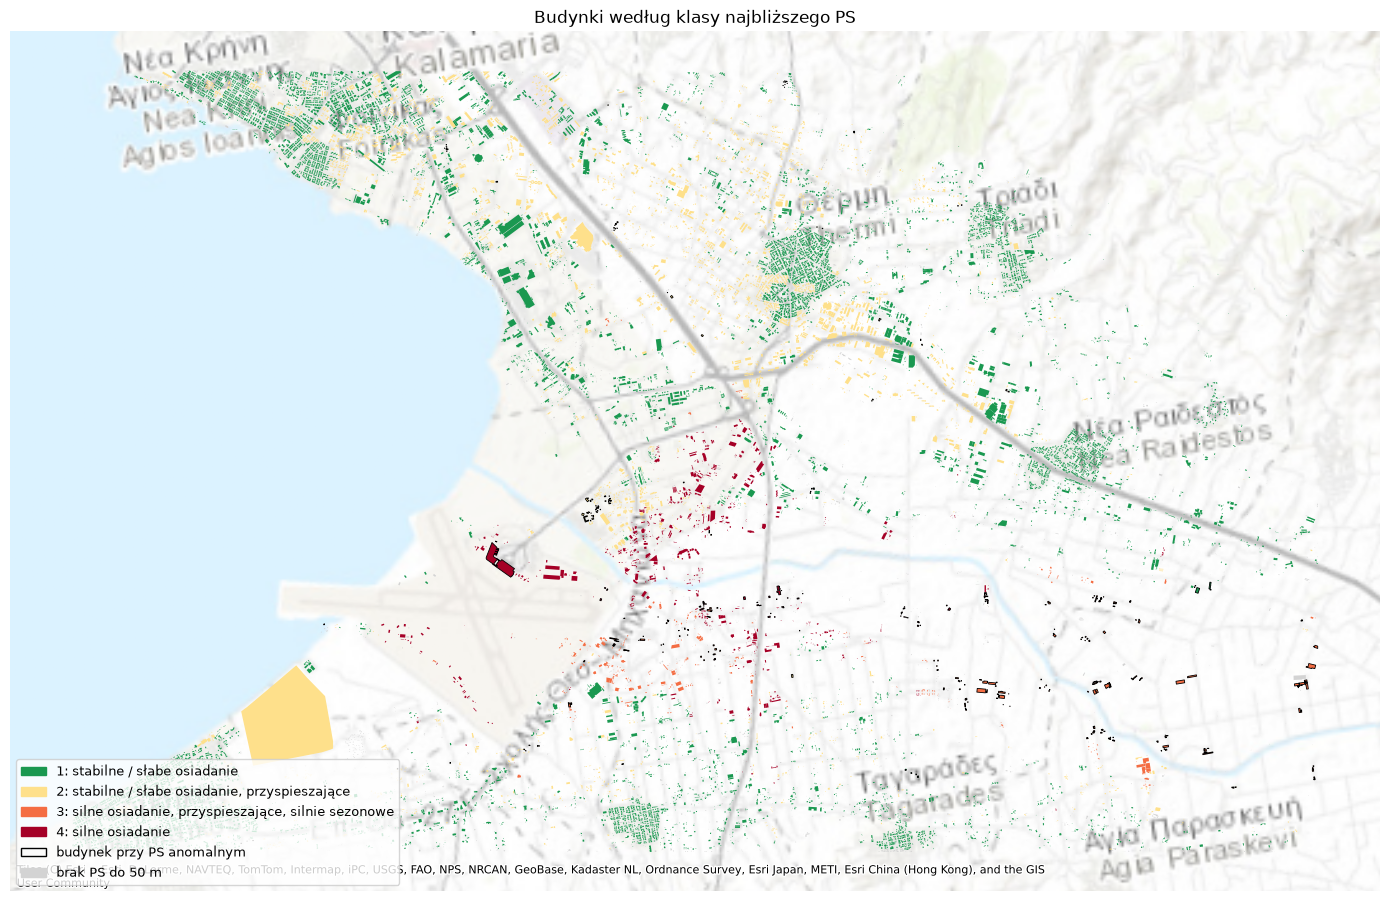

In [24]:
fig, ax = plt.subplots(figsize=(14, 11))
result[~matched].plot(ax=ax, color="lightgrey", linewidth=0)
for c in sorted(class_colors):
    result[result["cluster"] == c].plot(ax=ax, color=class_colors[c], linewidth=0)
result[result["anomaly"] == 1].plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.6)

handles = [plt.Rectangle((0, 0), 1, 1, color=class_colors[c]) for c in sorted(class_colors)]
handles += [plt.Rectangle((0, 0), 1, 1, facecolor="none", edgecolor="black"),
            plt.Rectangle((0, 0), 1, 1, color="lightgrey")]
labels = [cluster_summary.loc[c, "cluster_name"] for c in sorted(class_colors)] + [
    "budynek przy PS anomalnym", f"brak PS do {MAX_DISTANCE} m"]
ax.legend(handles, labels, loc="lower left", fontsize=9)
ax.set_title("Budynki według klasy najbliższego PS")
add_basemap(ax)
plt.tight_layout()
save_fig("mapa_budynki.png", dpi=200, bbox_inches="tight")
plt.show()

# 8. Eksport wyników

| plik | zawartość |
|---|---|
| `results/EGMS_Thessaloniki_PS_results.csv` | wszystkie PS z cechami, anomaly_score, anomalią i klasą |
| `results/EGMS_Thessaloniki_PS_results.gpkg` | to samo jako warstwy QGIS: punkty i kwadraty 100 m |
| `results/budynki_EGMS_results.gpkg` / `.csv` | budynki z przypisanym PS |
| `results/budynki_wymagajace_uwagi.csv` | budynki przy anomaliach / silnym osiadaniu |
| `results/podsumowanie_klas.csv`, `podsumowanie_budynkow.csv` | tabele do prezentacji |
| `maps/*.png`, `maps/mapa_interaktywna_PS.html` | mapy i wykresy |

In [25]:
ps_cols = (
    ["pid", "easting", "northing", "mean_velocity", "acceleration", "seasonality", "rmse_ts",
     "trend", "trend_R2"]
    + yearly_trend_cols
    + ["annual_trend_std", "baseline_velocity", "recent_velocity", "trend_change",
       "anomaly_score", "anomaly", "cluster", "cluster_name"]
)

df[ps_cols].to_csv(RESULTS_DIR / "EGMS_Thessaloniki_PS_results.csv", index=False, encoding="utf-8")

ps_gpkg = RESULTS_DIR / "EGMS_Thessaloniki_PS_results.gpkg"
ps_gdf[ps_cols + ["geometry"]].to_file(ps_gpkg, layer="PS_punkty", driver="GPKG")
ps_cells[ps_cols + ["geometry"]].to_file(ps_gpkg, layer="PS_komorki_100m", driver="GPKG")

result.to_file(RESULTS_DIR / "budynki_EGMS_results.gpkg", layer="budynki_EGMS", driver="GPKG")
result.drop(columns="geometry").to_csv(RESULTS_DIR / "budynki_EGMS_results.csv", index=False, encoding="utf-8")
risk.drop(columns="geometry").to_csv(RESULTS_DIR / "budynki_wymagajace_uwagi.csv", index=False, encoding="utf-8")

cluster_summary.to_csv(RESULTS_DIR / "podsumowanie_klas.csv", encoding="utf-8")
buildings_summary.to_csv(RESULTS_DIR / "podsumowanie_budynkow.csv", encoding="utf-8")

for f in sorted(RESULTS_DIR.iterdir()):
    print(f.name)

budynki_EGMS_results.csv
budynki_EGMS_results.gpkg
budynki_wymagajace_uwagi.csv
EGMS_Thessaloniki_PS_results.csv
EGMS_Thessaloniki_PS_results.gpkg
podsumowanie_budynkow.csv
podsumowanie_klas.csv


# 9. Interpretacja wyników

Obszar analizy: południowo-wschodnia część aglomeracji Salonik — Kalamaria i Nea Krini (wybrzeże), Thermi, Triadi, Nea Raidestos, lotnisko Makedonia oraz równina rolnicza Tagarades / Agia Paraskevi. 5625 punktów EGMS (siatka 100 m), 2020–2024.

**Ogólnie.** Przeważa słabe osiadanie (mediana `mean_velocity` −1,6 mm/rok), ale rozkład ma długi ogon do −27 mm/rok — w obszarze istnieje wyraźna strefa szybkiego osiadania.

**Lokalizacja 4 klas.**

| klasa | PS | mediana v [mm/rok] | gdzie leży |
|---|---|---|---|
| 1: stabilne / słabe osiadanie | 3076 (55%) | −1,3 | zabudowa Kalamarii i Nea Krini, Thermi, Triadi, Nea Raidestos, tereny wyżej położone na północnym wschodzie |
| 2: słabe osiadanie, przyspieszające | 1696 (30%) | −1,6 | rozproszone wśród klasy 1, głównie w północnej części (Thermi, okolice obwodnicy); w ostatnim roku tempo wzrosło (`trend_change` ≈ −3,3) |
| 3: silne osiadanie, przyspieszające, silnie sezonowe | 282 (5%) | −8,6 | równina na południe od lotniska i wzdłuż rzeki w stronę Tagarades / Agia Paraskevi — tereny rolnicze |
| 4: silne osiadanie | 571 (10%) | −10,0 | pas od wybrzeża przy lotnisku na wschód, przez strefę zabudowy na południe od węzła drogowego |

**Interpretacja.** Klasy 3 i 4 tworzą spójną strefę osiadania w niżej położonej równinie (dolina Anthemountas), a nie losowe pojedyncze punkty — to wskazuje na przyczynę o charakterze regionalnym. Klasa 3 ma bardzo silną sezonowość (mediana 4,9 mm vs 1,1 w całym zbiorze): teren obniża się latem i częściowo podnosi zimą. Taki wzór pasuje do **sezonowego poboru wód podziemnych** (nawadnianie pól latem) i kompakcji osadów — w literaturze osiadanie w basenie Anthemountas / rejonie lotniska Salonik wiązane jest właśnie z eksploatacją wód podziemnych. Klasa 4 osiada szybko, ale równomiernie (−10 mm/rok, prawie liniowo, ok. 5 cm w 5 lat). Na zachodnim krańcu klasy 4, na wybrzeżu przy lotnisku, jest zwarty blok komórek oznaczonych w całości jako anomalie — warto sprawdzić, czy to teren nasypowy / rozbudowa infrastruktury (konsolidacja świeżego nasypu).

**Anomalie (Isolation Forest).** 282 PS (5%). Koncentrują się w klasie 3 (42% jej punktów) i 4 (14%), a prawie nie występują w klasie 1 (0,5%). Anomalie to punkty z szybkim osiadaniem (mediana −10,2 mm/rok), dużym przyspieszeniem w ostatnim roku (−8,4 mm/rok) i silną sezonowością. Korelacja z `rmse_ts` jest słaba (0,30), więc anomalie nie wynikają głównie ze złej jakości danych. Model nie powiela też prostego rankingu prędkości: w TOP20 tylko 13 punktów pokrywa się z 20 najszybciej osiadającymi.

**Budynki.** 18 684 z 21 846 budynków (86%) ma PS w odległości do 50 m. Większość z nich (67%) leży w klasie 1. W strefach silnego osiadania (klasy 3 i 4) jest ok. 1500 budynków, a 375 budynków leży przy PS anomalnym — najwięcej w klasie 3 (35% budynków tej klasy). Lista budynków wymagających uwagi jest w `results/budynki_wymagajace_uwagi.csv`; najszybsze osiadanie przy budynkach to ok. −23 mm/rok.

**Ograniczenia.**
- Dane EGMS Ortho to siatka 100 m — wynik opisuje ruch terenu w otoczeniu budynku, nie konkretny budynek.
- Isolation Forest wskazuje punkty *nietypowe statystycznie*; 5% to umowny próg, a nie dowód zagrożenia.
- Brak danych naziemnych (np. niwelacji, GNSS) do walidacji wyników.
- Okres 2020–2024 — nie widać zmian sprzed 2020 r.